# 14. The hidden cost, and the crossover

Phase estimation does not prepare the ground state; it *projects* onto it. Started from a state $|\phi\rangle$,
it returns the ground energy with probability $\gamma^2 = |\langle\phi|E_0\rangle|^2$ and some other eigenvalue
otherwise. So the quantum price of notebook 13 has to be multiplied by about $1/\gamma^2$ repetitions. Where
does a good $|\phi\rangle$ come from? The natural answer is: from DMRG, with a bond dimension small enough to
be cheap. This notebook measures how good that is, then puts both prices on one plot.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from dmrg_from_scratch import j1j2_cylinder
from dmrg_from_scratch.resources import crossover, load_ladders, overlap_of
from dmrg_from_scratch import dmrg_ladder
from dmrg_from_scratch import ground_state
from dmrg_from_scratch import build_mpo
from dmrg_from_scratch import to_dense
from dmrg_from_scratch.resources import SECONDS_PER_TOFFOLI

## 1. A live run: overlap of a small MPS with the exact ground state

On the 4 x 4 cylinder we can compute $\gamma$ exactly. A product state ($\chi = 1$, the best Néel-like
configuration) has almost no overlap with the singlet ground state; a few units of bond dimension fix that.

In [2]:
H = j1j2_cylinder(4)
E0, psi0 = ground_state(H)
for r in dmrg_ladder(build_mpo(H), [1, 2, 4, 8, 16], n_sweeps=3):
    gamma = abs(to_dense(r["mps"]) @ psi0)
    print(f"chi = {r['chi']:2d}   gamma = {gamma:.4f}   QPE repetitions 1/gamma^2 = {1 / gamma**2:8.1f}")

chi =  1   gamma = 0.0861   QPE repetitions 1/gamma^2 =    134.9
chi =  2   gamma = 0.6448   QPE repetitions 1/gamma^2 =      2.4
chi =  4   gamma = 0.9192   QPE repetitions 1/gamma^2 =      1.2
chi =  8   gamma = 0.9598   QPE repetitions 1/gamma^2 =      1.1
chi = 16   gamma = 0.9987   QPE repetitions 1/gamma^2 =      1.0


## 2. Overlap shrinks exponentially with system size

At fixed $\chi$, each extra spin adds a little more error, and errors multiply: $\gamma \approx e^{-\kappa N}$.
This is the orthogonality catastrophe that Lee et al. [arXiv:2208.02199](https://arxiv.org/abs/2208.02199)
argue undermines many claims of exponential quantum advantage. For the wider cylinders the exact ground state is
unknown, so we use the overlap with the best ($\chi = 256$) MPS instead (from `python scripts/make_results.py`,
about two hours on 4 cores).

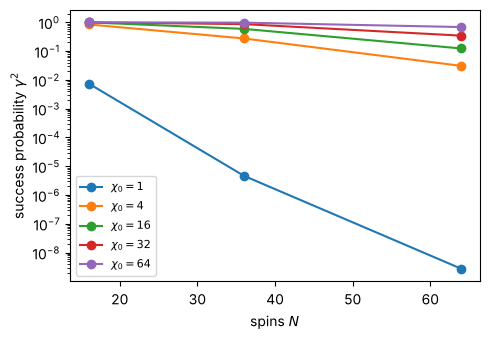

In [3]:
ladders = [lad for lad in load_ladders() if lad["W"] % 2 == 0]
N = np.array([lad["n"] for lad in ladders])
fig, ax = plt.subplots(figsize=(5, 3.5))
for chi0 in [1, 4, 16, 32, 64]:
    ax.semilogy(N, [overlap_of(lad, chi0) ** 2 for lad in ladders], "o-", label=rf"$\chi_0 = {chi0}$")
ax.set(xlabel="spins $N$", ylabel=r"success probability $\gamma^2$")
ax.legend(fontsize=8)
fig.tight_layout()

The product state is hopeless: at 64 spins it would need hundreds of millions of repetitions. An MPS with $\chi_0 = 32$,
which costs a fraction of a second classically and $\sim N\chi_0^2$ gates to load, keeps $\gamma^2$ of order
one at these sizes, and decays slowly. We fit $\kappa$ and extrapolate.

## 3. The crossover

Now both prices, against width. Classical: the bond dimension DMRG needs for $\epsilon = 0.01$, extrapolated
from $W = 6, 8$ (notebook 12). Quantum: qubitized QPE to the same $\epsilon$ (notebook 13), times
$1/\gamma^2$ for a $\chi_0 = 32$ start. The bands span the hardware assumptions: $10^{11}$ to $10^{13}$ flop/s
classically, 170 µs to 1.7 µs per Toffoli.

170.0 us/Toffoli, 1e+11 flop/s: quantum wins from W = 8 (64 spins), where QPE takes 4.9 hours
170.0 us/Toffoli, 1e+12 flop/s: quantum wins from W = 9 (90 spins), where QPE takes 13.3 hours
170.0 us/Toffoli, 1e+13 flop/s: quantum wins from W = 10 (100 spins), where QPE takes 18.2 hours
  1.7 us/Toffoli, 1e+11 flop/s: quantum wins from W = 6 (36 spins), where QPE takes 46 seconds
  1.7 us/Toffoli, 1e+12 flop/s: quantum wins from W = 7 (56 spins), where QPE takes 2.1 minutes
  1.7 us/Toffoli, 1e+13 flop/s: quantum wins from W = 8 (64 spins), where QPE takes 3.0 minutes


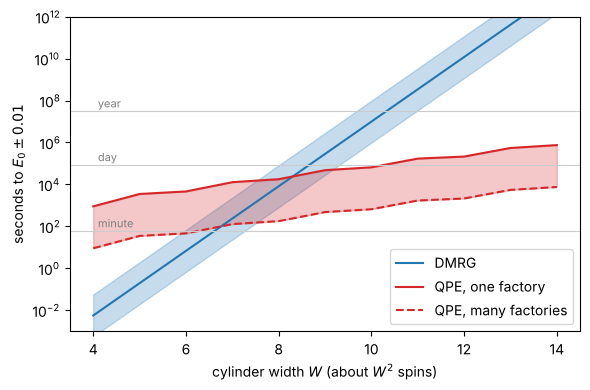

In [4]:
ladders = load_ladders()
widths = np.arange(4, 15)
runs = {(t, f): crossover(ladders, chi0=32, seconds_per_toffoli=t, flops_per_second=f, widths=widths)
        for t in SECONDS_PER_TOFFOLI.values() for f in (1e11, 1e12, 1e13)}
slow, fast = SECONDS_PER_TOFFOLI["one factory"], SECONDS_PER_TOFFOLI["many factories"]
day = 24 * 3600

fig, ax = plt.subplots(figsize=(6, 4))
ax.fill_between(widths, runs[slow, 1e11]["classical"], runs[slow, 1e13]["classical"], alpha=0.25, color="C0")
ax.semilogy(widths, runs[slow, 1e12]["classical"], color="C0", label="DMRG")
ax.fill_between(widths, runs[slow, 1e12]["quantum"], runs[fast, 1e12]["quantum"], alpha=0.25, color="C3")
ax.semilogy(widths, runs[slow, 1e12]["quantum"], color="C3", label="QPE, one factory")
ax.semilogy(widths, runs[fast, 1e12]["quantum"], color="C3", ls="--", label="QPE, many factories")
for t, lab in [(60, "minute"), (day, "day"), (365 * day, "year")]:
    ax.axhline(t, color="0.8", lw=0.8)
    ax.text(4.1, t * 1.5, lab, color="0.5", fontsize=8)
ax.set(xlabel="cylinder width $W$ (about $W^2$ spins)", ylabel="seconds to $E_0 \\pm 0.01$", ylim=(1e-3, 1e12))
ax.legend(loc="lower right")
fig.tight_layout()


def human(seconds):
    for unit, size in [("days", day), ("hours", 3600), ("minutes", 60)]:
        if seconds >= size:
            return f"{seconds / size:.1f} {unit}"
    return f"{seconds:.0f} seconds"


for (t, f), r in runs.items():
    W = r["W_star"]
    print(f"{t * 1e6:5.1f} us/Toffoli, {f:.0e} flop/s: quantum wins from W = {W} "
          f"({W * (W + W % 2)} spins), where QPE takes {human(r['quantum'][list(widths).index(W)])}")

The two curves have different shapes: DMRG is a straight line on the log plot (exponential in $W$), QPE bends
over (polynomial, $\sim N^2$ times a slowly growing $1/\gamma^2$). They cross between $W = 6$ and $W = 10$, that is
36 to 100 spins, where the quantum computer needs between minutes and a day. Below that, DMRG wins easily; above
it, the gap opens by more than an order of magnitude per unit of width.

This agrees in spirit with the much more careful study of Yoshioka et al.
[arXiv:2210.14109](https://arxiv.org/abs/2210.14109), who find the crossover for 2D Heisenberg-type models at
system sizes of tens to a hundred spins.

## 4. What this estimate leaves out

* **Better classical codes.** SU(2) symmetry, better initial states and parallel DMRG all shift the blue line
  down; the slope stays.
* **Better quantum algorithms.** Lower one-norms (e.g. grouping terms), better block encodings and
  statistical phase estimation shift the red line down.
* **Error correction overhead.** Logical qubits are a few hundred here; with distance-30 surface code that is
  hundreds of thousands of physical qubits.
* **The extrapolations.** Both classical cost and overlap are fitted on $W = 6, 8$ only. The exercises probe how
  much the crossover moves.

## Exercises

1. Start QPE from $\chi_0 = 16$ or $64$ instead of 32. How much does the crossover move? Is the overlap or the
   gate count the bigger lever?
2. Ask for $\epsilon = 0.001$. DMRG needs a larger $\chi$, QPE needs 10 times more calls. Who suffers more?
3. Pass `fit_widths=(4, 6, 8)` to `crossover`. How sensitive is $W^*$ to the classical extrapolation?
4. Suppose a better classical method makes DMRG $10^3$ times faster at every width. How many units of width
   does that buy it?